# Empirical arbitrage: LP refit and frozen out-of-sample validation

This notebook fits three deterministic portfolios on the 40,000-path sample and evaluates each **unchanged** on the independent 400,000-path sample. The LP searches for $\beta$ maximizing mean net payoff subject to non-negative net payoff on every training path and $|\beta_{t,\ell}|\leq1$.

The net payoff is
$$\beta\cdot dX_\omega-|\beta|\cdot(\delta\,\mathrm{MCError}_{train}+p|X_\omega|),$$
where $\mathrm{MCError}_{train}=\mathrm{std}(dX_{train},\mathrm{ddof}=1)/\sqrt{40000}$. The materiality threshold is **$10^{-8}$**; smaller results are treated as numerical zero.

In [ ]:
from pathlib import Path
import json
import subprocess
import sys

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MATERIALITY = 1e-8
TRAINING_H5 = Path('/tmp/.noarbtest/40,000.h5')
VALIDATION_H5 = Path('/tmp/.noarbtest/400,000.h5')
REPO = Path.cwd() if (Path.cwd() / 'refit_and_validate_arbitrage_fast.py').is_file() else Path.cwd().parent
OUTPUT = REPO / 'paper' / 'arbitrage_validation_results'
SCRIPT = REPO / 'refit_and_validate_arbitrage_fast.py'
assert SCRIPT.is_file(), SCRIPT
assert TRAINING_H5.is_file(), TRAINING_H5
assert VALIDATION_H5.is_file(), VALIDATION_H5
OUTPUT.mkdir(parents=True, exist_ok=True)
REPO, OUTPUT

(PosixPath('/mnt/c/Users/hans/OneDrive/Python3/quant_data'),
 PosixPath('/mnt/c/Users/hans/OneDrive/Python3/quant_data/paper/arbitrage_validation_results'))

## Inspect inputs

The time and instrument dimensions must agree. The validation sample may contain more paths.

In [ ]:
dataset_rows = []
for label, path in [('training', TRAINING_H5), ('validation', VALIDATION_H5)]:
    with h5py.File(path, 'r') as h5:
        for key in ('root/dX', 'root/X'):
            ds = h5[key]
            dataset_rows.append({'sample': label, 'key': key, 'shape': ds.shape, 'dtype': str(ds.dtype)})
dataset_table = pd.DataFrame(dataset_rows)
display(dataset_table)
assert dataset_rows[0]['shape'][1:] == dataset_rows[2]['shape'][1:]
assert dataset_rows[0]['shape'] == dataset_rows[1]['shape']
assert dataset_rows[2]['shape'] == dataset_rows[3]['shape']

,sample,key,shape,dtype
0,training,root/dX,"(40000, 9, 141)",float32
1,training,root/X,"(40000, 9, 141)",float32
2,validation,root/dX,"(400000, 9, 141)",float32
3,validation,root/X,"(400000, 9, 141)",float32


## Run the LPs and frozen validation

The runner uses violated-constraint generation rather than constructing the full doubled dense LP. It prints a timestamped line after every LP iteration and every 100,000 validation paths, so long-running execution visibly remains alive. Existing completed experiments in the output directory are reused; delete that directory if a completely fresh refit is desired.

In [ ]:
command = [
    sys.executable, str(SCRIPT),
    '--training-h5', str(TRAINING_H5),
    '--validation-h5', str(VALIDATION_H5),
    '--output-dir', str(OUTPUT),
]
print('Running:', ' '.join(command), flush=True)
completed = subprocess.run(command, cwd=REPO, check=False)
if completed.returncode:
    raise RuntimeError(f'LP/validation runner failed with exit code {completed.returncode}')

Running: /home/hans/vaae/bin/python3 /mnt/c/Users/hans/OneDrive/Python3/quant_data/refit_and_validate_arbitrage_fast.py --training-h5 /tmp/.noarbtest/40,000.h5 --validation-h5 /tmp/.noarbtest/400,000.h5 --output-dir /mnt/c/Users/hans/OneDrive/Python3/quant_data/paper/arbitrage_validation_results


[13:51:59] loading 40,000-path training arrays


[13:52:00] starting delta0_prop0: delta=0, prop_cost=0


[13:52:01] iteration 1: active=1,000, mean=0.0982175573, min=-0.117134031, violations=2,511


[13:52:05] iteration 2: active=2,000, mean=0.0778708327, min=-0.0383576764, violations=239


[13:52:09] iteration 3: active=2,239, mean=0.075549804, min=-0.009831406, violations=13


... (22 outputs left out)

[13:53:51] validation progress: 100,000/400,000 paths


[13:53:52] validation progress: 200,000/400,000 paths


[13:53:53] validation progress: 300,000/400,000 paths


[13:53:54] validation progress: 400,000/400,000 paths
[13:53:54] finished delta0_prop1bp: validation min=-0.0287448966, mean=0.0603823149, negative=996
[13:53:54] all experiments complete; results in /mnt/c/Users/hans/OneDrive/Python3/quant_data/paper/arbitrage_validation_results


## Results at the $10^{-8}$ materiality threshold

Statistics below are recomputed directly from the saved pathwise payoff arrays. A material training certificate requires minimum payoff at least $-10^{-8}$ and mean payoff greater than $10^{-8}$.

In [ ]:
summary = json.loads((OUTPUT / 'summary.json').read_text())
labels = {
    'delta0_prop0': 'No cost',
    'delta1_prop0': '1 training MC error',
    'delta0_prop1bp': '1 bp of X',
}
rows = []
payoffs = {}
for name, label in labels.items():
    train = np.load(OUTPUT / f'{name}_training_payoff.npy')
    valid = np.load(OUTPUT / f'{name}_validation_payoff.npy')
    payoffs[name] = (train, valid)
    for sample, values in [('40k training', train), ('400k frozen', valid)]:
        mean = float(values.mean())
        minimum = float(values.min())
        negative = int(np.sum(values < -MATERIALITY))
        rows.append({
            'cost': label, 'sample': sample, 'minimum': minimum, 'mean': mean,
            'material negative paths': negative,
            'material negative fraction': negative / values.size,
            'pathwise certificate': minimum >= -MATERIALITY and mean > MATERIALITY,
        })
results = pd.DataFrame(rows)
display(results.style.format({
    'minimum': '{:.9g}', 'mean': '{:.9g}', 'material negative fraction': '{:.4%}'
}))

,cost,sample,minimum,mean,material negative paths,material negative fraction,pathwise certificate
0,No cost,40k training,-1.00001882e-10,0.0754442508,0,0.0000%,True
1,No cost,400k frozen,-0.0375552878,0.0755699217,874,0.2185%,False
2,1 training MC error,40k training,-2.39866869e-10,9.42036913e-10,0,0.0000%,False
3,1 training MC error,400k frozen,-3.88567479e-09,9.45140181e-10,0,0.0000%,False
4,1 bp of X,40k training,-2.99546343e-10,0.0602909257,0,0.0000%,True
5,1 bp of X,400k frozen,-0.0287448966,0.0603823149,996,0.2490%,False


In [ ]:
solver_rows = []
for name, label in labels.items():
    experiment = summary['experiments'][name]
    solver = experiment['solver']
    solver_rows.append({
        'cost': label, 'status': solver['solver_message'],
        'iterations': solver['iterations'], 'active constraints': solver['active_constraints'],
        'violated paths after full check': solver['violated_paths'],
        'LP seconds': solver['elapsed_seconds'],
        'L1(beta)': experiment['l1_beta'], 'max abs(beta)': experiment['max_abs_beta'],
    })
solver_table = pd.DataFrame(solver_rows)
display(solver_table.style.format({'LP seconds': '{:.1f}', 'L1(beta)': '{:.6g}', 'max abs(beta)': '{:.6g}'}))

,cost,status,iterations,active constraints,violated paths after full check,LP seconds,L1(beta),max abs(beta)
0,No cost,Optimization terminated successfully. (HiGHS Status 7: Optimal),5,2255,0,17.1,1223.6,1
1,1 training MC error,Optimization terminated successfully. (HiGHS Status 7: Optimal),6,3012,0,60.4,4.0996e-05,1.88044e-06
2,1 bp of X,Optimization terminated successfully. (HiGHS Status 7: Optimal),5,2426,0,21.5,975.82,1


## Validation payoff distributions

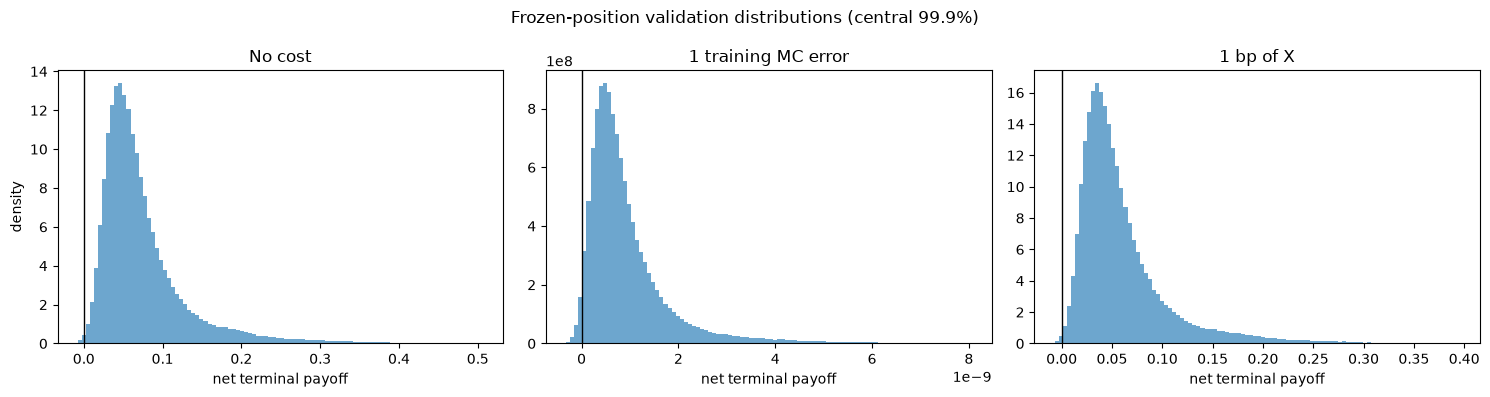

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, label) in zip(axes, labels.items()):
    train, valid = payoffs[name]
    lo, hi = np.quantile(valid, [0.0005, 0.9995])
    ax.hist(valid, bins=100, range=(lo, hi), density=True, alpha=.65, label='400k frozen')
    ax.axvline(0, color='black', linewidth=1)
    ax.set_title(label)
    ax.set_xlabel('net terminal payoff')
axes[0].set_ylabel('density')
fig.suptitle('Frozen-position validation distributions (central 99.9%)')
fig.tight_layout()
plt.show()

## Conclusion

At a $10^{-8}$ materiality threshold:

- The 40k sample has material empirical separating portfolios with no cost and with 1 bp cost.
- Neither frozen material portfolio remains pathwise non-negative on the 400k independent sample. Their validation means remain positive, so they are expected-payoff signals with risk rather than arbitrages.
- The delta=1 LP collapses to numerical zero: its training and validation means, losses, and fitted position scale are immaterial. It is not a real arbitrage certificate.
- The evidence supports finite-sample separation, not structural model arbitrage.